# ViT · 03-2: ViT Shapley für Unsicherheit

- **Voraussetzungen:** [03-0](keith_03-0_vit-probly.ipynb) und [03-1](keith_03-1_uncertainty-explainer.ipynb).
- **Problem:** Eine Erklärung in 03-1 braucht **1000 Koalitionen** je Bild, also 1000 Läufe durch beide
  Transformer. Auf einer CPU sind das etwa zwei Minuten je Bild. Für eine Anwendung, die jedes neue Bild sofort
  erklären soll, ist das zu langsam.
- **Idee von ViT Shapley** (Covert, Kim & Lee, ICLR 2023): Man trainiert **einmal** ein eigenes Modell, den
  *Erklärer*, das aus einem Bild direkt die Shapley-Werte vorhersagt. Danach kostet eine Erklärung nur noch
  **einen** Vorwärtslauf.
- **Der Trick:** Der Erklärer braucht zum Training **keine** echten Shapley-Werte. Shapley-Werte sind die Lösung von

  $$\min_\phi \; \mathbb{E}_{S \sim \text{Shapley-Kern}} \Big[\big(v(S) - v(\emptyset) - \textstyle\sum_{i \in S} \phi_i\big)^2\Big]
  \quad\text{mit}\quad \textstyle\sum_i \phi_i = v(N) - v(\emptyset).$$

  Man braucht also nur Spielwerte v(S) für zufällige Koalitionen. Die haben wir schon: die ausgeblendeten
  Trainingsbilder aus 03-0.

**Was wir gegenüber Covert et al. ändern** (und was daran neu ist):

| | ViT Shapley (Covert et al.) | unsere Version |
|---|---|---|
| Was wird erklärt? | eine Klassenwahrscheinlichkeit | **P, TU, AU und EU** eines probly-Modells gleichzeitig |
| Spieler | festes Kachelraster | **SLIC-Superpixel** (von den Autoren als offene Richtung genannt) |
| Erklärer | ein ganzer, nachtrainierter ViT, ein Wert je Patch | kleiner Transformer auf **Spieler-Tokens**: die eingefrorenen ViT-Tokens jedes Superpixels gemittelt (CPU, Minuten) |
| Ersatzmodell (Surrogat) | nachtrainierter ViT | maskiert trainierte Köpfe aus 03-0 |

**Vorab festgelegte Frage F7:** Erreicht der lernende Erklärer für jede der vier Größen im Median mindestens die
Genauigkeit von KernelSHAP mit **256** Koalitionen? Genauigkeit wird gegen eine KernelSHAP-Referenz mit 2048
Koalitionen gemessen (13 Testbilder der Teilmenge, Hauptmethode `Gemischt`, maskierte Köpfe).

## 0. Setup

In [1]:
from __future__ import annotations

import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from scipy.stats import spearmanr

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "probly").is_dir())
PACKAGE_DIR = REPO_ROOT / "experiments" / "group-d_experiments" / "keith_03_vit_uncertainty"
sys.path.insert(0, str(PACKAGE_DIR))

from vit_uncertainty import (
    AmortizedUncertaintyExplainer,
    CoalitionFeatures,
    FeatureLayout,
    OxfordPets,
    UncertaintyExplainer,
    build_methods,
    default_data_root,
    load_backbones,
    regions_to_tokens,
    settings,
)
from vit_uncertainty.amortized import QUANTITY_ORDER
from vit_uncertainty.features import (
    ARTIFACT_DIR,
    coalition_cache,
    full_image_features,
    load,
    masked_training_features,
    save,
    save_coalition_cache,
)
from vit_uncertainty.plot import show_values
from vit_uncertainty.probly_bridge import uncertainty

torch.set_num_threads(max(1, torch.get_num_threads()))
FIGURES = PACKAGE_DIR / "figures"
FIGURES.mkdir(exist_ok=True)
pets = OxfordPets(default_data_root())
backbones = load_backbones()
layout = FeatureLayout.from_backbones(backbones)
stored = load(ARTIFACT_DIR / "heads.pt")
if stored is None:
    raise FileNotFoundError("heads.pt fehlt. Bitte zuerst keith_03-0_vit-probly.ipynb ausführen.")
predictor = build_methods(layout, stored["heads"]["maskiert"], n_members=settings.N_MEMBERS)["Gemischt"]
train_pos, val_pos = pets.train_val_indices
full = {split: full_image_features(pets, backbones, split, verbose=False) for split in ("trainval", "test")}
masked = {
    "train": masked_training_features(
        pets, backbones, train_pos, name="train", per_image=settings.MASKED_PER_IMAGE_TRAIN, verbose=False
    ),
    "val": masked_training_features(
        pets, backbones, val_pos, name="val", per_image=settings.MASKED_PER_IMAGE_VAL, verbose=False
    ),
}
print("Daten geladen.")

Daten geladen.


## 1. Trainingsdaten für den Erklärer

Für jedes Trainingsbild brauchen wir:

- die **Patch-Tokens** des eingefrorenen ViT für das ganze Bild (Eingabe des Erklärers, 196 × 384 Zahlen),
- zu welchem **Superpixel** jedes Token gehört (die Ausgabe wird je Superpixel aufsummiert),
- **v(N)** (ganzes Bild) und **v(∅)** (alles ausgeblendet; bei Token-Weglassen für jedes Bild gleich),
- für 8 zufällige Koalitionen S die Spielwerte **v(S)** für P, TU, AU und EU.

P ist die Wahrscheinlichkeit der Klasse, die das Modell auf dem ganzen Bild vorhersagt.

In [2]:
empty_x = layout.concat(
    {
        name: b.features(np.zeros((1, 224, 224, 3), np.uint8), np.zeros((1, b.n_patches), bool))
        for name, b in backbones.items()
    }
)
empty_scores = uncertainty(predictor, empty_x)


def game_values(scores: dict, target: np.ndarray) -> torch.Tensor:
    # Stack P (probability of each row's target class), TU, AU, EU into (rows, 4).
    p = scores["probabilities"][np.arange(len(target)), target]
    return torch.from_numpy(np.stack([p, scores["TU"], scores["AU"], scores["EU"]], axis=1)).float()


def dataset(split: str) -> dict:
    m = masked[split]
    images = m["image_positions"].numpy()
    full_x = layout.concat({n: full["trainval"]["features"][n][images] for n in layout.names})
    full_scores = uncertainty(predictor, full_x)
    target = full_scores["probabilities"].argmax(1)  # explained class per image
    rows = torch.arange(len(images)).repeat_interleave(len(m["positions"]) // len(images))
    masked_scores = uncertainty(predictor, layout.concat(m["features"]))
    return {
        "tokens": full["trainval"]["vit_tokens"][images],
        "token_players": m["token_players"]["vit"],
        "empty_per_image": game_values({k: np.repeat(v, len(images), axis=0) for k, v in empty_scores.items()}, target),
        "full": game_values(full_scores, target),
        "rows": rows,
        "coalitions": m["coalitions"],
        "values": game_values(masked_scores, target[rows.numpy()]),
    }


data = {split: dataset(split) for split in ("train", "val")}
for split in data:
    # v(empty) of P depends on the explained class; we subtract it per image (see below).
    data[split]["empty"] = torch.zeros(4)
    data[split]["full"] = data[split]["full"] - data[split]["empty_per_image"]
    data[split]["values"] = data[split]["values"] - data[split]["empty_per_image"][data[split]["rows"]]
print({split: {"Bilder": len(d["tokens"]), "Koalitionen": len(d["rows"])} for split, d in data.items()})

{'train': {'Bilder': 2944, 'Koalitionen': 23552}, 'val': {'Bilder': 736, 'Koalitionen': 2944}}


**Ein Detail:** v(∅) ist bei Token-Weglassen für jedes Bild gleich, **außer bei P**: P ist die Wahrscheinlichkeit
der jeweils erklärten Klasse, und die hängt vom Bild ab. Wir ziehen deshalb v(∅) je Bild ab und trainieren auf
v(S) − v(∅). An den Shapley-Werten ändert das nichts.

## 2. Den Erklärer trainieren

- **Spieler-Tokens:** Die 196 eingefrorenen ViT-Tokens werden je Superpixel gemittelt; dazu kommt der Flächenanteil
  des Superpixels. Das ergibt 16 Spieler-Tokens je Bild. Ein erster Versuch mit Attention über alle 196 Tokens war
  auf der CPU zu langsam (geschätzt 1 bis 2 Stunden Training); mit 16 Spieler-Tokens sind es Minuten.
- Kleiner Transformer: **eine Schicht, Breite 32**. Jeder Spieler sieht über Attention alle anderen, sein Wert kann
  also vom ganzen Bild abhängen, wie ein Shapley-Wert. Ausgabe: 4 Werte je Spieler (P, TU, AU, EU).
- **Warum so klein?** Ein erster Lauf mit 2 Schichten und Breite 128 lernte die Trainingsbilder auswendig: Der
  Trainingsfehler sank, der Validierungsfehler stieg ab der ersten Epoche. Wir haben danach vier Größen und
  Regularisierungen verglichen (Breite 16 bis 128, Weight Decay bis 0,1, Dropout). Alle landeten beim selben
  Validierungsfehler; das kleine Netz ist am schnellsten. Das Problem ist also nicht die Netzgröße, sondern die
  **Datenmenge** (Abschnitt 3.1).
- Danach verteilt die **additive effiziente Normalisierung** (Covert et al.) den fehlenden Rest gleichmäßig, sodass
  Σφ = v(N) − v(∅) **immer exakt** gilt.
- Jede Größe wird mit ihrer Streuung skaliert, damit P (0 bis 1) und EU (um 0,05) gleich viel zählen.
- Der Validierungsverlust wählt die beste Epoche. Das Ergebnis wird gespeichert.

Passenden Erklärer aus amortized.pt geladen.


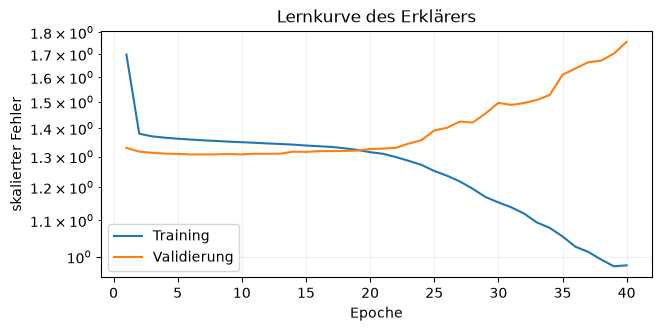

In [3]:
AMORTIZED_PATH = ARTIFACT_DIR / "amortized.pt"
amortized_manifest = {
    "heads": stored["manifest"],
    "masked": [masked[s]["manifest"] for s in masked],
    "epochs": 40,
    "lr": 1e-3,
    "weight_decay": 1e-2,
    "width": 32,
    "depth": 1,
    "seed": settings.SEED,
}
amortized = AmortizedUncertaintyExplainer(settings.N_PLAYERS, seed=settings.SEED)
cached = load(AMORTIZED_PATH)
if cached is not None and cached["manifest"] == amortized_manifest:
    amortized.load_state_dict(cached["state"])
    print("Passenden Erklärer aus amortized.pt geladen.")
else:
    start = time.perf_counter()
    amortized.fit(data["train"], data["val"], epochs=40, lr=1e-3, weight_decay=1e-2)
    save(AMORTIZED_PATH, {"manifest": amortized_manifest, "state": amortized.state_dict()})
    print(f"Training: {time.perf_counter() - start:.0f} s")
history = pd.DataFrame(amortized.history)
fig, ax = plt.subplots(figsize=(6.5, 3.2), layout="constrained")
ax.plot(history["epoch"], history["train_loss"], label="Training")
ax.plot(history["epoch"], history["val_loss"], label="Validierung")
ax.set(xlabel="Epoche", ylabel="skalierter Fehler", yscale="log", title="Lernkurve des Erklärers")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 3. F7: Wie genau ist der Erklärer im Vergleich zu KernelSHAP?

Auf den 13 Testbildern der Teilmenge (der Erklärer hat sie nie gesehen):

- **Referenz:** KernelSHAP aus shapiq mit **2048** Koalitionen (von 65.536 möglichen). Auch die Referenz ist eine
  Näherung; exakt wäre hier zu teuer.
- **KernelSHAP** mit 64, 128, 256 und 512 Koalitionen.
- **Lernender Erklärer:** ein Vorwärtslauf.
- **Gleichverteilung** als einfachste Vergleichsgröße: Jedes Superpixel bekommt ein Sechzehntel von v(N) − v(∅).
  Ein Erklärer, der nicht besser ist, hat nichts über das Bild gelernt.

Fehlermaß je Bild und Größe: relativer Fehler ‖φ − φ_Referenz‖ / ‖φ_Referenz‖ (0 = perfekt). Alle Shapley-Werte
erfüllen die Effizienz, die Summen sind also gleich; verglichen wird die **Verteilung** auf die Superpixel.

In [4]:
subset = [pets.test[0][pets.cohorts["explanation"][i]] for i in settings.SUBSET_POSITIONS]
test_index = {image_id: i for i, image_id in enumerate(pets.test[0])}
sv = {}
for image_id in subset:
    cache = coalition_cache(pets, image_id, backbones)
    for budget in [*settings.SV_BUDGETS, settings.SV_REFERENCE_BUDGET]:
        ex = UncertaintyExplainer(
            backbones,
            predictor,
            players="slic",
            n_players=settings.N_PLAYERS,
            index="SV",
            max_order=1,
            budget=budget,
            random_state=settings.SEED,
        )
        sv[(image_id, budget)] = ex.explain(cache.image, regions=cache.regions, coalition_features=cache)
    save_coalition_cache(cache)

# Cost of one coalition (both transformers), measured once on this computer.
probe = sv[(subset[0], settings.SV_REFERENCE_BUDGET)]
fresh = CoalitionFeatures(probe.image, probe.regions, backbones)  # empty cache: really runs the transformers
start = time.perf_counter()
fresh(np.random.default_rng(1).random((32, settings.N_PLAYERS)) < 0.5)
seconds_per_coalition = (time.perf_counter() - start) / 32


def amortized_explain(image_id: str) -> tuple[np.ndarray, float]:
    # One forward pass of the explainer. Its full cost also includes one pass of the full image through
    # both transformers (for the ViT tokens and for v(N)); that pass costs `seconds_per_coalition`.
    reference = sv[(image_id, settings.SV_REFERENCE_BUDGET)]
    tokens = full["test"]["vit_tokens"][test_index[image_id]][None]
    token_players = torch.from_numpy(regions_to_tokens(reference.regions, backbones["vit"].patch_size))[None]
    gap = torch.tensor([[reference.full[q] - reference.empty[q] for q in QUANTITY_ORDER]])
    start = time.perf_counter()
    phi = amortized.explain(tokens, token_players, gap, torch.zeros(4))[0]
    return phi, time.perf_counter() - start + seconds_per_coalition


def relative_error(estimate: np.ndarray, reference: np.ndarray) -> float:
    return float(np.linalg.norm(estimate - reference) / (np.linalg.norm(reference) + 1e-12))


rows, amortized_phi, amortized_time = [], {}, []
for image_id in subset:
    amortized_phi[image_id], t = amortized_explain(image_id)
    amortized_time.append(t)
    reference = sv[(image_id, settings.SV_REFERENCE_BUDGET)]
    for q_index, quantity in enumerate(QUANTITY_ORDER):
        ref = reference.first_order(quantity)
        for budget in settings.SV_BUDGETS:
            rows.append(
                {
                    "Bild": image_id,
                    "Größe": quantity,
                    "Verfahren": f"KernelSHAP {budget}",
                    "Fehler": relative_error(sv[(image_id, budget)].first_order(quantity), ref),
                }
            )
        rows.append(
            {
                "Bild": image_id,
                "Größe": quantity,
                "Verfahren": "Lernender Erklärer",
                "Fehler": relative_error(amortized_phi[image_id][:, q_index], ref),
                "ρ": float(spearmanr(amortized_phi[image_id][:, q_index], ref).statistic),
            }
        )
        uniform = np.full(len(ref), (reference.full[quantity] - reference.empty[quantity]) / len(ref))
        rows.append(
            {
                "Bild": image_id,
                "Größe": quantity,
                "Verfahren": "Gleichverteilung",
                "Fehler": relative_error(uniform, ref),
            }
        )
errors = pd.DataFrame(rows)
table = errors.pivot_table(index="Verfahren", columns="Größe", values="Fehler", aggfunc="median")[list(QUANTITY_ORDER)]
order = [f"KernelSHAP {b}" for b in settings.SV_BUDGETS] + ["Lernender Erklärer", "Gleichverteilung"]
table = table.loc[order]
cost = pd.Series(
    {f"KernelSHAP {b}": b * seconds_per_coalition for b in settings.SV_BUDGETS}
    | {"Lernender Erklärer": float(np.median(amortized_time)), "Gleichverteilung": 0.0},
    name="Sekunden je Bild",
)
display(Markdown("**Median des relativen Fehlers gegen KernelSHAP mit 2048 Koalitionen (13 Testbilder)**"))
formats = dict.fromkeys(QUANTITY_ORDER, "{:.2f}") | {"Sekunden je Bild": "{:.3f}"}
display(pd.concat([table, cost], axis=1).style.format(formats))
F7 = all(table.loc["Lernender Erklärer", q] <= table.loc["KernelSHAP 256", q] for q in QUANTITY_ORDER)
display(
    Markdown(
        f"**F7 nach der Regel: {'gestützt' if F7 else 'nicht gestützt'}.** "
        f"Kosten einer Koalition auf diesem Rechner: {seconds_per_coalition * 1000:.0f} ms (beide Netze)."
    )
)

**Median des relativen Fehlers gegen KernelSHAP mit 2048 Koalitionen (13 Testbilder)**

,P,TU,AU,EU,Sekunden je Bild
KernelSHAP 64,1.33,1.60,1.71,0.84,7.121
KernelSHAP 128,0.60,0.67,0.74,0.73,14.242
KernelSHAP 256,0.46,0.56,0.61,0.48,28.484
KernelSHAP 512,0.34,0.45,0.48,0.36,56.969
Lernender Erklärer,0.62,0.52,0.49,0.89,0.112
Gleichverteilung,0.76,0.63,0.60,0.95,0.000


**F7 nach der Regel: nicht gestützt.** Kosten einer Koalition auf diesem Rechner: 111 ms (beide Netze).

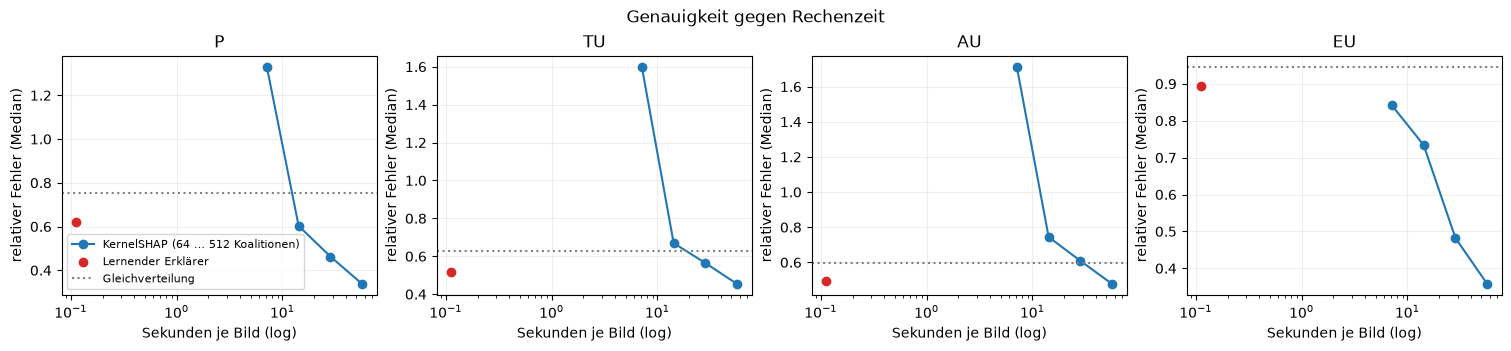

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), layout="constrained")
for ax, quantity in zip(axes, QUANTITY_ORDER, strict=True):
    budgets = settings.SV_BUDGETS
    ax.plot(
        [b * seconds_per_coalition for b in budgets],
        table.loc[[f"KernelSHAP {b}" for b in budgets], quantity],
        marker="o",
        label="KernelSHAP (64 … 512 Koalitionen)",
    )
    ax.scatter(
        [cost["Lernender Erklärer"]],
        [table.loc["Lernender Erklärer", quantity]],
        color="tab:red",
        zorder=3,
        label="Lernender Erklärer",
    )
    ax.axhline(table.loc["Gleichverteilung", quantity], color="0.5", linestyle=":", label="Gleichverteilung")
    ax.set(xscale="log", title=quantity, xlabel="Sekunden je Bild (log)", ylabel="relativer Fehler (Median)")
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
fig.suptitle("Genauigkeit gegen Rechenzeit")
fig.savefig(FIGURES / "vit_shapley_genauigkeit_zeit.png", dpi=110)
plt.show()

### 3.1 Wie viel Daten braucht der Erklärer?

Neue Koalitionen kosten Transformer-Läufe. Wir können aber prüfen, ob **mehr** Daten helfen würden, indem wir mit
**weniger** trainieren: 2, 4 oder 8 Koalitionen je Bild und 25, 50 oder 100 % der Trainingsbilder. Wird der Fehler
auf den 13 Testbildern mit mehr Daten kleiner, lohnt es sich, mehr Koalitionen zu erzeugen
(`settings.MASKED_PER_IMAGE_TRAIN`, z. B. auf einem schnelleren Rechner).

,Koalitionen je Bild,Anteil Bilder,Koalitionen gesamt,P,TU,AU,EU
0,2,25%,1472,0.73,0.55,0.55,1.10
1,2,50%,2944,0.74,0.54,0.54,1.07
2,2,100%,5888,0.72,0.58,0.56,0.99
3,4,25%,2944,0.69,0.53,0.53,1.02
4,4,50%,5888,0.71,0.53,0.50,1.02
5,4,100%,11776,0.69,0.50,0.47,0.98
6,8,25%,5888,0.71,0.54,0.52,0.95
7,8,50%,11776,0.64,0.53,0.48,0.96
8,8,100%,23552,0.62,0.52,0.49,0.89


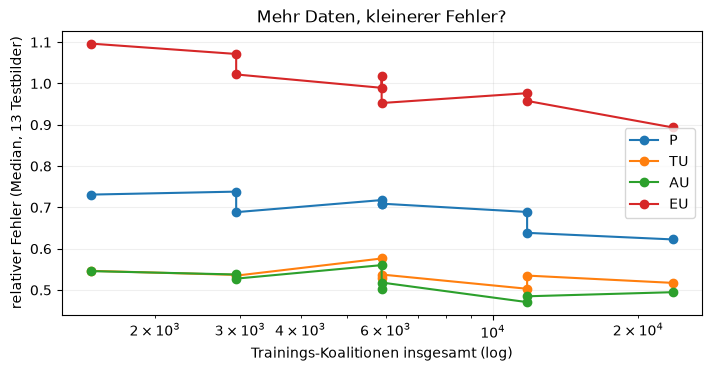

In [6]:
def reduced(d: dict, per_image: int, fraction: float) -> dict:
    # Keep `per_image` coalitions of a random `fraction` of the training images (seeded).
    rng = np.random.default_rng(settings.SEED)
    n_images = len(d["tokens"])
    keep = np.sort(rng.choice(n_images, size=round(fraction * n_images), replace=False))
    per = len(d["rows"]) // n_images
    rows = [i * per + j for i in keep for j in range(per_image)]
    new_index = {old: new for new, old in enumerate(keep)}
    return {
        "tokens": d["tokens"][keep],
        "token_players": d["token_players"][keep],
        "empty": d["empty"],
        "full": d["full"][keep],
        "rows": torch.tensor([new_index[int(r)] for r in d["rows"][rows]]),
        "coalitions": d["coalitions"][rows],
        "values": d["values"][rows],
    }


def test_error(model: AmortizedUncertaintyExplainer) -> dict:
    errors_ = {q: [] for q in QUANTITY_ORDER}
    for image_id in subset:
        reference = sv[(image_id, settings.SV_REFERENCE_BUDGET)]
        tokens = full["test"]["vit_tokens"][test_index[image_id]][None]
        token_players = torch.from_numpy(regions_to_tokens(reference.regions, backbones["vit"].patch_size))[None]
        gap = torch.tensor([[reference.full[q] - reference.empty[q] for q in QUANTITY_ORDER]])
        phi = model.explain(tokens, token_players, gap, torch.zeros(4))[0]
        for q_index, quantity in enumerate(QUANTITY_ORDER):
            errors_[quantity].append(relative_error(phi[:, q_index], reference.first_order(quantity)))
    return {q: float(np.median(v)) for q, v in errors_.items()}


curve = []
for per_image in (2, 4, 8):
    for fraction in (0.25, 0.5, 1.0):
        model = AmortizedUncertaintyExplainer(settings.N_PLAYERS, seed=settings.SEED)
        train_part = reduced(data["train"], per_image, fraction)
        model.fit(train_part, data["val"], epochs=40, lr=1e-3, weight_decay=1e-2, verbose=False)
        curve.append(
            {
                "Koalitionen je Bild": per_image,
                "Anteil Bilder": fraction,
                "Koalitionen gesamt": len(train_part["rows"]),
                **test_error(model),
            }
        )
curve = pd.DataFrame(curve)
display(curve.style.format({"Anteil Bilder": "{:.0%}", **dict.fromkeys(QUANTITY_ORDER, "{:.2f}")}))

fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
for quantity in QUANTITY_ORDER:
    ordered = curve.sort_values("Koalitionen gesamt")
    ax.plot(ordered["Koalitionen gesamt"], ordered[quantity], marker="o", label=quantity)
ax.set(
    xscale="log",
    xlabel="Trainings-Koalitionen insgesamt (log)",
    ylabel="relativer Fehler (Median, 13 Testbilder)",
    title="Mehr Daten, kleinerer Fehler?",
)
ax.legend()
ax.grid(alpha=0.2)
fig.savefig(FIGURES / "vit_shapley_lernkurve.png", dpi=110)
plt.show()

## 4. Wie sehen die Karten aus?

Drei Testbilder: oben die Referenz (KernelSHAP, 2048 Koalitionen), unten der lernende Erklärer (ein Durchlauf).

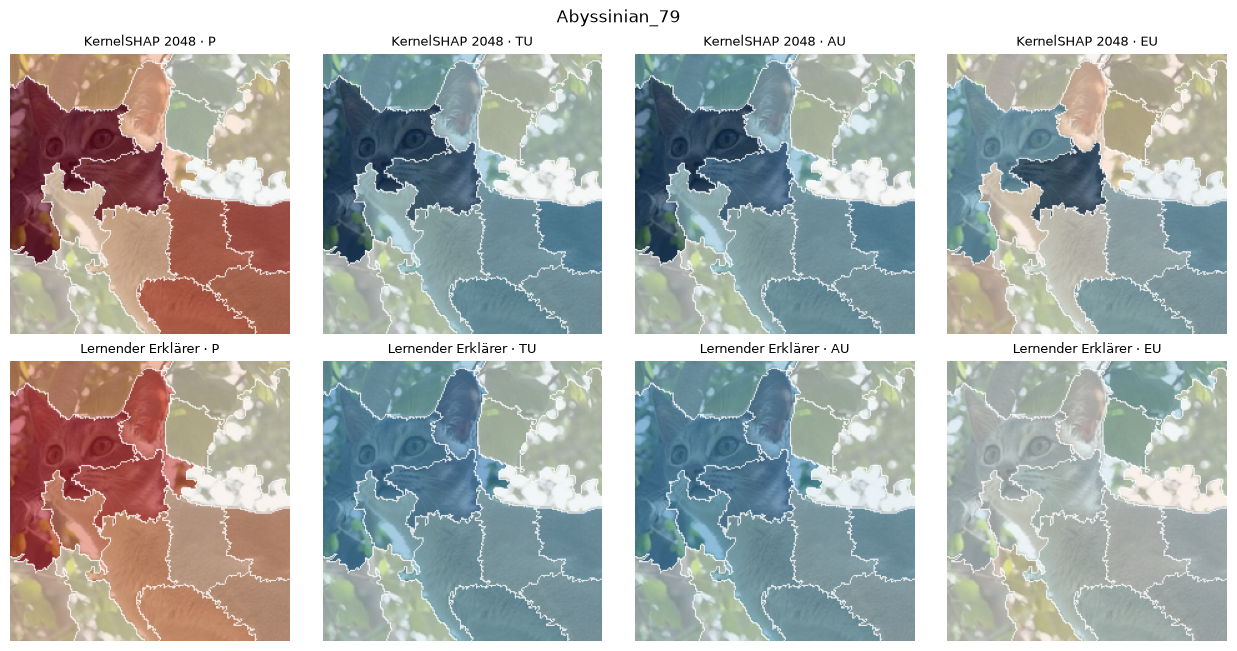

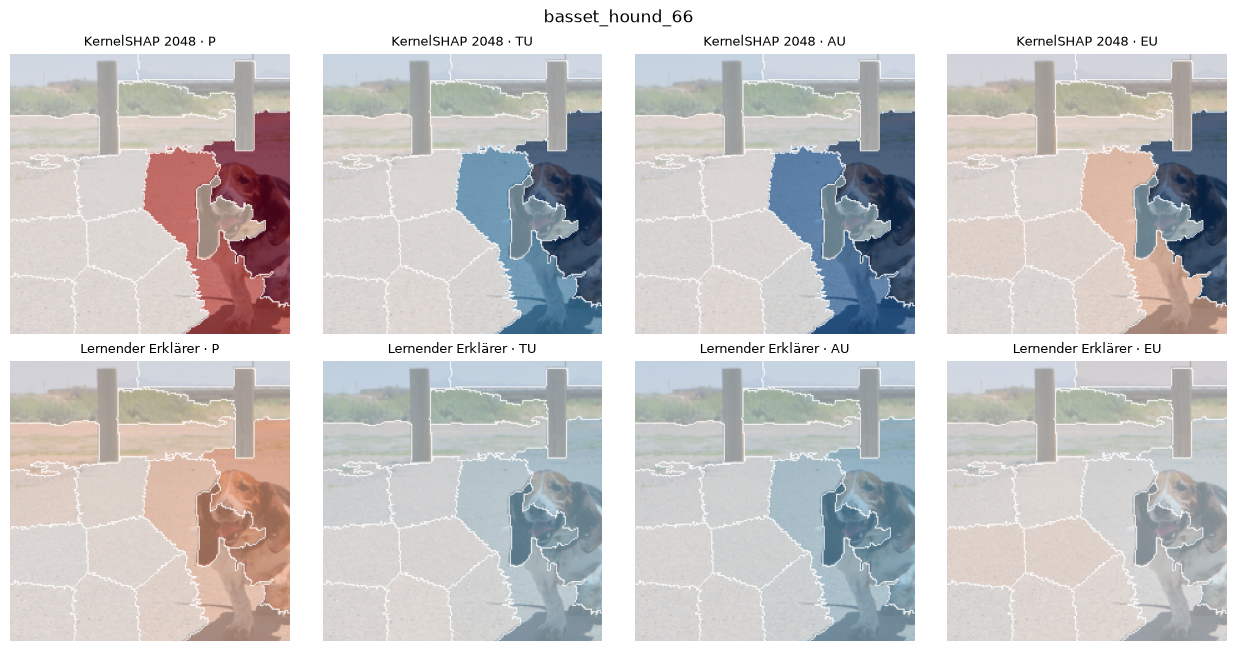

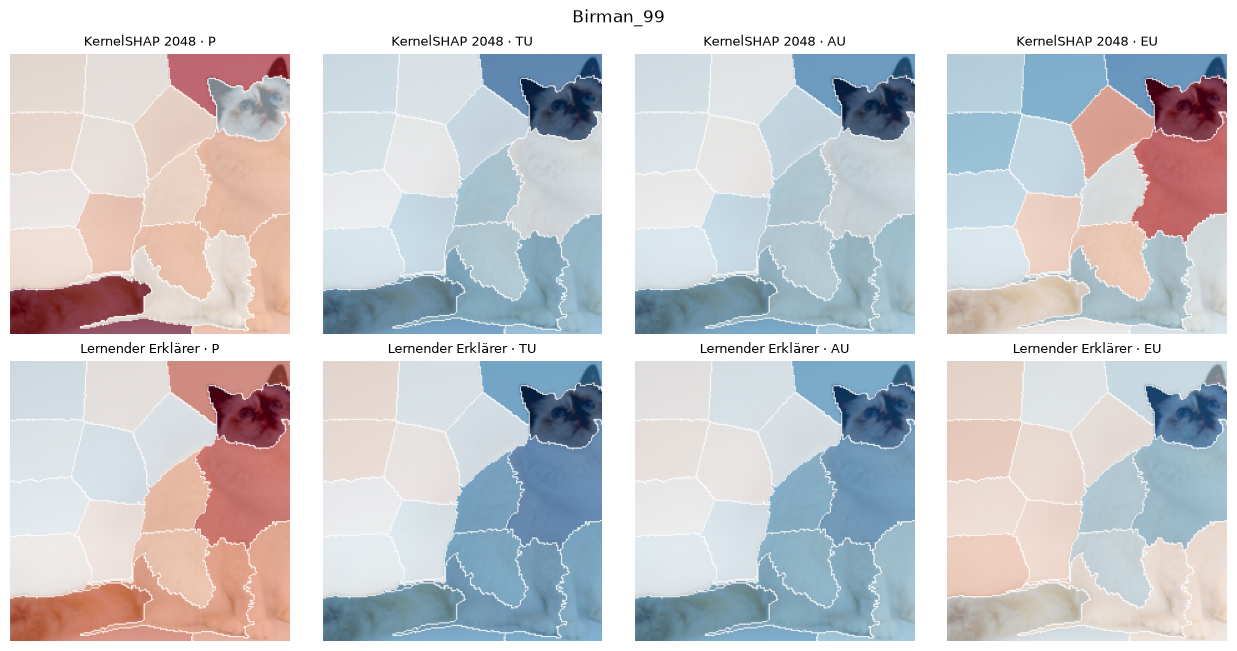

In [7]:
for image_id in subset[:3]:
    reference = sv[(image_id, settings.SV_REFERENCE_BUDGET)]
    fig, axes = plt.subplots(2, 4, figsize=(12.5, 6.4), layout="constrained")
    for column, quantity in enumerate(QUANTITY_ORDER):
        ref = reference.first_order(quantity)
        est = amortized_phi[image_id][:, column]
        vmax = max(np.abs(ref).max(), np.abs(est).max())
        show_values(
            axes[0, column], reference.image, reference.regions, ref, vmax=vmax, title=f"KernelSHAP 2048 · {quantity}"
        )
        show_values(
            axes[1, column],
            reference.image,
            reference.regions,
            est,
            vmax=vmax,
            title=f"Lernender Erklärer · {quantity}",
        )
    fig.suptitle(f"{image_id}")
    fig.savefig(FIGURES / f"vit_shapley_{image_id}.png", dpi=100)
    plt.show()

## 5. Ergebnis und was wir daraus lernen

In [8]:
display(
    pd.DataFrame(
        {
            "Frage": ["F7 lernender Erklärer mindestens so genau wie KernelSHAP 256"],
            "Kennzahl": [
                "; ".join(
                    f"{q}: {table.loc['Lernender Erklärer', q]:.2f} gegen {table.loc['KernelSHAP 256', q]:.2f}"
                    for q in QUANTITY_ORDER
                )
            ],
            "Ergebnis": ["gestützt" if F7 else "nicht gestützt"],
        }
    ).set_index("Frage")
)

,Kennzahl,Ergebnis
Frage,,
F7 lernender Erklärer mindestens so genau wie KernelSHAP 256,P: 0.62 gegen 0.46; TU: 0.52 gegen 0.56; AU: 0...,nicht gestützt


**Was die Ergebnisse in einfachen Worten sagen** (Zahlen aus unserem Lauf, siehe Tabellen oben)

1. **Der Erklärer lernt etwas, aber für P und EU noch nicht genug.** Er ist bei allen vier Größen besser als die
   Gleichverteilung (P 0,62 gegen 0,76; TU 0,52 gegen 0,63; AU 0,49 gegen 0,60; EU 0,89 gegen 0,95). Für **TU und AU**
   ist er sogar **genauer als KernelSHAP mit 256 Koalitionen** (0,52 gegen 0,56 und 0,49 gegen 0,61), für P und EU nicht
   (0,62 gegen 0,46 und 0,89 gegen 0,48). **F7 ist damit nicht gestützt.**
2. **Er ist sehr schnell.** Eine Erklärung kostet etwa 0,1 s je Bild. Fast die ganze Zeit ist der eine Lauf des ganzen
   Bildes durch beide Netze (111 ms auf dem Rechner, auf dem dieses Notebook lief); der Erklärer selbst kostet höchstens
   etwa eine Millisekunde. KernelSHAP mit 256 Koalitionen braucht 256 solcher Läufe, also etwa 28 s: gut 250-mal so
   lange.
3. **Er braucht mehr Daten.** Von der kleinsten zur größten Datenmenge sinkt der Fehler für P (0,73 → 0,62) und EU
   (1,10 → 0,89); TU und AU liegen schon mit wenig Daten bei etwa 0,5. Mit 8 Koalitionen je Bild, aber 16 unbekannten
   Werten, ist das Lernziel für jedes einzelne Bild unterbestimmt. Das passt dazu, dass der erste, größere Erklärer die
   Trainingsbilder auswendig gelernt hat und kleinere Netze oder mehr Regularisierung nichts änderten (Abschnitt 2).
4. **Warum ist EU am schwersten?** Eine mögliche Erklärung: EU hängt stark an Kombinationen von Bildteilen (in 03-1 ist
   das Verhältnis von Paar- zu Einzelbeiträgen bei EU doppelt so groß wie bei P). Eine additive Erklärung trifft die
   einzelnen Koalitionswerte eines solchen Spiels schlecht, und mit wenigen Koalitionen je Bild streut das Lernsignal
   stark.

**Was das für die Leitfrage bedeutet**

- Schnelle Unsicherheits-Erklärungen sind möglich: Für die Gesamtunsicherheit (TU) und das Rauschen (AU) liefert **ein**
  Durchlauf schon Karten auf dem Niveau von KernelSHAP mit 256 Koalitionen. Für fehlendes Wissen (EU) braucht man mehr
  Trainingsdaten oder ein besseres Lernsignal.

**Was das für unser Projekt bedeutet**

- **Mögliches Endthema:** „Amortisierte Unsicherheitserklärungen“. Neu gegenüber ViT Shapley sind vier Größen
  gleichzeitig (P, TU, AU, EU) eines probly-Modells und Superpixel als Spieler.
- **Nächster Schritt auf einem schnelleren Rechner:** `settings.MASKED_PER_IMAGE_TRAIN = 32` setzen (viermal so viele
  Trainings-Koalitionen) und alle drei Notebooks neu ausführen. Achtung: Die Einstellung ändert auch die maskierten
  Köpfe aus 03-0, also alle Ergebnisse. Weitere Ideen: gepaarte Koalitionen (S zusammen mit seinem Komplement ziehen,
  wie bei Covert et al.) und den Erklärer auch die DINOv2-Tokens sehen lassen.
- Abbildungen für die Präsentation: `figures/vit_shapley_genauigkeit_zeit.png`, `figures/vit_shapley_lernkurve.png`.

**Grenzen**

- Die Referenz ist selbst eine Näherung (KernelSHAP mit 2048 von 65.536 Koalitionen).
- 13 Testbilder; nur die Hauptmethode (gemischtes Ensemble, maskierte Köpfe).
- Die Zeiten gelten für den Rechner, auf dem das Notebook lief (2 CPU-Kerne). Das Verhältnis von etwa 1 zu 256 hängt
  kaum vom Rechner ab, weil beide Zeiten fast nur aus Transformer-Läufen bestehen.
- Der Erklärer arbeitet auf gemittelten Tokens je Superpixel; er ist ein Prototyp, kein fertiges Verfahren.